In [18]:
from pathlib import Path
import numpy as np
import pandas as pd
import xgboost as xgb
import shap

from pathlib import Path
import xgboost as xgb

model_dir = Path("../outputs/models")

xgb_tuned_2018 = xgb.XGBClassifier()
xgb_tuned_2018.load_model(
    model_dir / "xgb_tuned_2018.json"
)

print("2018 tuned XGBoost model loaded.")

2018 tuned XGBoost model loaded.


In [20]:
processed_dir_2018 = Path("../data/processed/cicids18")
processed_files_2018 = sorted(processed_dir_2018.glob("*.parquet"))

df_2018 = pd.concat(
    [pd.read_parquet(file_path) for file_path in processed_files_2018],
    ignore_index=True
)

feature_columns_2018 = np.load(
    "../outputs/splits/feature_columns_2018.npy",
    allow_pickle=True
).tolist()

train_idx_2018 = np.load(
    "../outputs/splits/2018_train_idx.npy"
)

test_idx_2018 = np.load(
    "../outputs/splits/2018_test_idx.npy"
)

print("2018 data shape:", df_2018.shape)
print("Number of features:", len(feature_columns_2018))
print("Training rows:", len(train_idx_2018))
print("Test rows:", len(test_idx_2018))

2018 data shape: (6659532, 71)
Number of features: 68
Training rows: 5271544
Test rows: 1317886


In [21]:
feature_hashes_2018 = pd.util.hash_pandas_object(
    df_2018[feature_columns_2018].astype(np.float64),
    index=False
)

print("Feature hashes created:", len(feature_hashes_2018))

Feature hashes created: 6659532


In [22]:
hash_target_counts_2018 = (
    pd.DataFrame({
        "Hash": feature_hashes_2018,
        "Target": df_2018["Target"]
    })
    .groupby("Hash")["Target"]
    .nunique()
)

conflicting_hash_values_2018 = hash_target_counts_2018[
    hash_target_counts_2018 > 1
].index

print("Conflicting fingerprint groups:", len(conflicting_hash_values_2018))

Conflicting fingerprint groups: 21947


In [23]:
conflicting_group_mask_2018 = feature_hashes_2018.isin(
    conflicting_hash_values_2018
)

print("Rows in conflicting groups:", conflicting_group_mask_2018.sum())

print("\nTarget distribution:")
print(
    df_2018.loc[
        conflicting_group_mask_2018,
        "Target"
    ].value_counts().sort_index()
)

Rows in conflicting groups: 70102

Target distribution:
Target
0    44005
1    26097
Name: count, dtype: int64


In [24]:
df_2018_clean = df_2018.loc[
    ~conflicting_group_mask_2018
].copy()

print("Clean rows:", len(df_2018_clean))
print("Clean attack rate:", df_2018_clean["Target"].mean())

Clean rows: 6589430
Clean attack rate: 0.19795748645937508


In [25]:
X_train_2018 = df_2018_clean.iloc[
    train_idx_2018
][feature_columns_2018]

y_train_2018 = df_2018_clean.iloc[
    train_idx_2018
]["Target"]

print("X_train_2018 shape:", X_train_2018.shape)
print("y_train_2018 shape:", y_train_2018.shape)
print("Training attack rate:", y_train_2018.mean())

X_train_2018 shape: (5271544, 68)
y_train_2018 shape: (5271544,)
Training attack rate: 0.19795737264072916


In [26]:
from sklearn.model_selection import train_test_split

X_shap_2018, _, y_shap_2018, _ = train_test_split(
    X_train_2018,
    y_train_2018,
    test_size=len(X_train_2018) - 100000,
    stratify=y_train_2018,
    random_state=42
)

print("SHAP sample shape:", X_shap_2018.shape)
print("SHAP sample attack rate:", y_shap_2018.mean())

SHAP sample shape: (100000, 68)
SHAP sample attack rate: 0.19796


In [27]:
explainer_2018 = shap.TreeExplainer(xgb_tuned_2018)

shap_values_2018 = explainer_2018.shap_values(
    X_shap_2018
)

print("SHAP values shape:", shap_values_2018.shape)

SHAP values shape: (100000, 68)


In [28]:
shap_importance_2018 = pd.DataFrame({
    "Feature": feature_columns_2018,
    "Mean_Abs_SHAP": np.abs(shap_values_2018).mean(axis=0)
})

shap_importance_2018 = shap_importance_2018.sort_values(
    "Mean_Abs_SHAP",
    ascending=False
).reset_index(drop=True)

print(shap_importance_2018.head(20).to_string(index=False))

                 Feature  Mean_Abs_SHAP
      Init Fwd Win Bytes       0.980902
Fwd Packets Length Total       0.545460
   Fwd Packet Length Max       0.458569
          ECE Flag Count       0.447636
             Bwd IAT Min       0.426286
      Init Bwd Win Bytes       0.409480
   Fwd Packet Length Std       0.391987
   Bwd Packet Length Std       0.364140
        Fwd Seg Size Min       0.268566
           Fwd IAT Total       0.251354
       Packet Length Max       0.244626
            Flow IAT Min       0.242584
           Flow Duration       0.227390
          RST Flag Count       0.207261
   Bwd Packet Length Max       0.177846
            Flow IAT Max       0.152809
           Fwd Packets/s       0.129206
Bwd Packets Length Total       0.118372
             Fwd IAT Min       0.115929
            Flow Bytes/s       0.114438


In [29]:
X_test_2018 = df_2018_clean.iloc[
    test_idx_2018
][feature_columns_2018]

y_test_2018 = df_2018_clean.iloc[
    test_idx_2018
]["Target"]

print("X_test_2018 shape:", X_test_2018.shape)
print("y_test_2018 shape:", y_test_2018.shape)
print("Test attack rate:", y_test_2018.mean())

X_test_2018 shape: (1317886, 68)
y_test_2018 shape: (1317886,)
Test attack rate: 0.19795794173395878


In [30]:
X_shap_test_2018, _, y_shap_test_2018, _ = train_test_split(
    X_test_2018,
    y_test_2018,
    test_size=len(X_test_2018) - 100000,
    stratify=y_test_2018,
    random_state=42
)

print("Test SHAP sample shape:", X_shap_test_2018.shape)
print("Test SHAP sample attack rate:", y_shap_test_2018.mean())

Test SHAP sample shape: (100000, 68)
Test SHAP sample attack rate: 0.19796


In [31]:
shap_values_test_2018 = explainer_2018.shap_values(
    X_shap_test_2018
)

print("Test SHAP values shape:", shap_values_test_2018.shape)

Test SHAP values shape: (100000, 68)


In [32]:
shap_importance_test_2018 = pd.DataFrame({
    "Feature": feature_columns_2018,
    "Mean_Abs_SHAP": np.abs(shap_values_test_2018).mean(axis=0)
})

shap_importance_test_2018 = shap_importance_test_2018.sort_values(
    "Mean_Abs_SHAP",
    ascending=False
).reset_index(drop=True)

print(
    shap_importance_test_2018.head(20).to_string(index=False)
)

                 Feature  Mean_Abs_SHAP
      Init Fwd Win Bytes       0.987888
Fwd Packets Length Total       0.542619
   Fwd Packet Length Max       0.450361
          ECE Flag Count       0.444885
             Bwd IAT Min       0.423658
      Init Bwd Win Bytes       0.408306
   Fwd Packet Length Std       0.384680
   Bwd Packet Length Std       0.362557
        Fwd Seg Size Min       0.269540
           Fwd IAT Total       0.250340
            Flow IAT Min       0.243479
       Packet Length Max       0.242977
           Flow Duration       0.229792
          RST Flag Count       0.206404
   Bwd Packet Length Max       0.177448
            Flow IAT Max       0.153741
           Fwd Packets/s       0.130038
Bwd Packets Length Total       0.117581
             Fwd IAT Min       0.116484
            Flow Bytes/s       0.114232


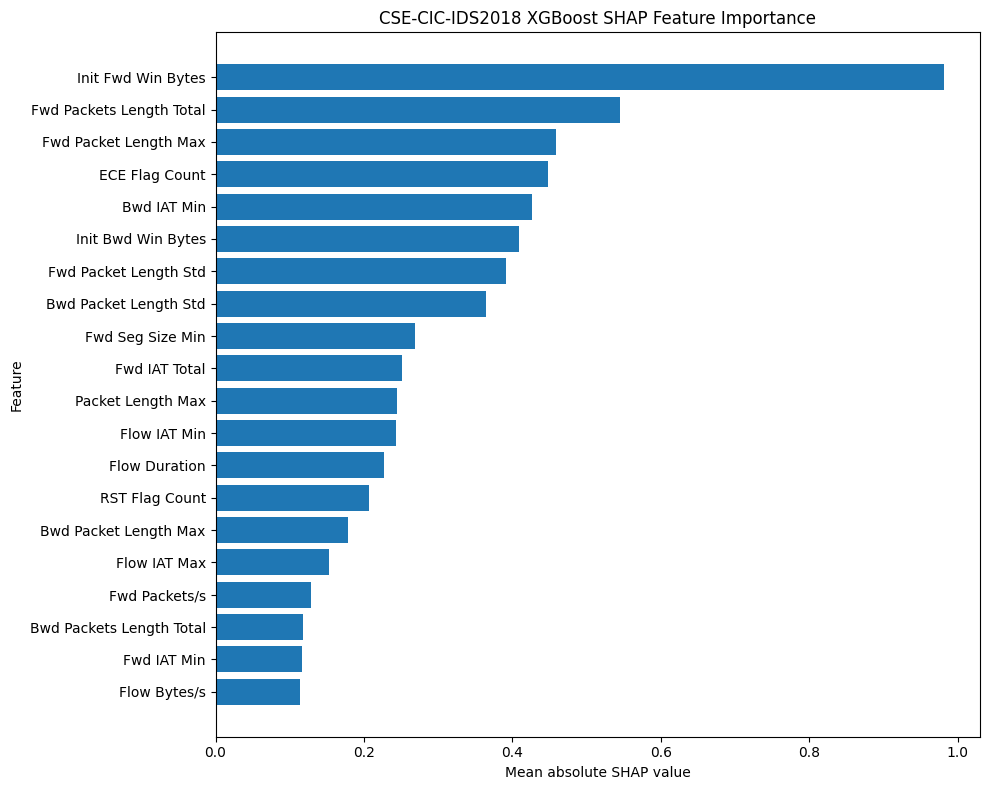

In [ ]:
import matplotlib.pyplot as plt

top20_shap_2018 = shap_importance_2018.head(20).sort_values(
    "Mean_Abs_SHAP"
)

plt.figure(figsize=(10, 8))
plt.barh(
    top20_shap_2018["Feature"],
    top20_shap_2018["Mean_Abs_SHAP"]
)
plt.xlabel("Mean absolute SHAP value")
plt.ylabel("Feature")
plt.title("CSE-CIC-IDS2018 XGBoost SHAP Feature Importance")
plt.tight_layout()
plt.show()

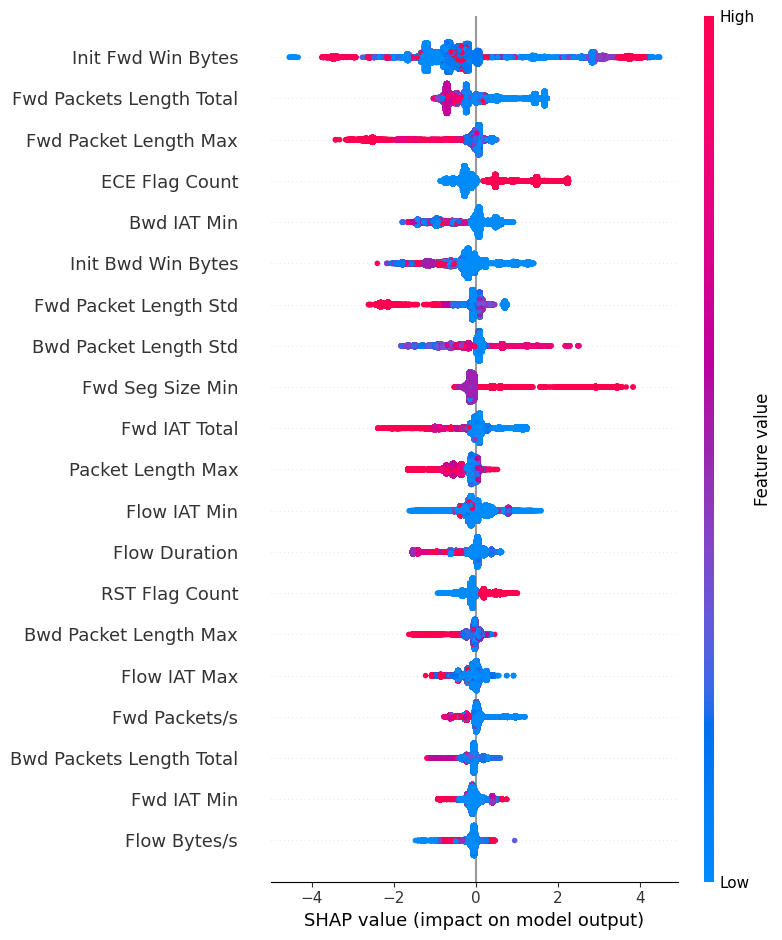

In [ ]:
shap.summary_plot(
    shap_values_2018,
    X_shap_2018,
    feature_names=feature_columns_2018,
    max_display=20,
    show=True
)

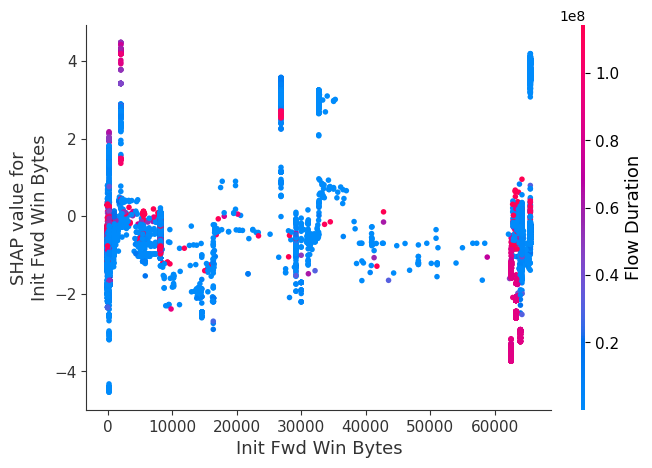

In [ ]:
shap.dependence_plot(
    "Init Fwd Win Bytes",
    shap_values_2018,
    X_shap_2018,
    feature_names=feature_columns_2018,
    show=True
)

2017 SHAP ANALYSIS


In [33]:
from pathlib import Path
import numpy as np
import pandas as pd
import xgboost as xgb
import shap

processed_dir_2017 = Path("../data/processed/cicids17")
processed_files_2017 = sorted(processed_dir_2017.glob("*.parquet"))

df_2017 = pd.concat(
    [pd.read_parquet(file_path) for file_path in processed_files_2017],
    ignore_index=True
)

feature_columns_2017 = np.load(
    "../outputs/splits/feature_columns_2017.npy",
    allow_pickle=True
).tolist()

train_idx_2017 = np.load(
    "../outputs/splits/retained_train_idx.npy"
)

test_idx_2017 = np.load(
    "../outputs/splits/retained_test_idx.npy"
)

print("2017 data shape:", df_2017.shape)
print("Number of features:", len(feature_columns_2017))
print("Training rows:", len(train_idx_2017))
print("Test rows:", len(test_idx_2017))

2017 data shape: (2830743, 71)
Number of features: 68
Training rows: 2264594
Test rows: 566149


In [34]:
X_train_2017 = df_2017_retained.iloc[
    train_idx_2017
][feature_columns_2017]

y_train_2017 = df_2017_retained.iloc[
    train_idx_2017
]["Target"]

print("X_train shape:", X_train_2017.shape)
print("y_train shape:", y_train_2017.shape)
print("Training attack rate:", y_train_2017.mean())

X_train shape: (2264594, 68)
y_train shape: (2264594,)
Training attack rate: 0.19699601782924445


In [ ]:
import xgboost as xgb

xgb_tuned_2017 = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    subsample=1.0,
    colsample_bytree=0.8,
    min_child_weight=1,
    scale_pos_weight=1.0,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_tuned_2017.fit(
    X_train_2017,
    y_train_2017
)

print("2017 tuned XGBoost training complete.")

2017 tuned XGBoost training complete.


In [ ]:
from pathlib import Path

model_dir = Path("../outputs/models")
model_dir.mkdir(parents=True, exist_ok=True)

xgb_tuned_2017.save_model(
    model_dir / "xgb_tuned_2017.json"
)

print("2017 tuned XGBoost model saved.")

2017 tuned XGBoost model saved.


In [35]:
from sklearn.model_selection import train_test_split

X_shap_2017, _, y_shap_2017, _ = train_test_split(
    X_train_2017,
    y_train_2017,
    train_size=100000,
    stratify=y_train_2017,
    random_state=42
)

print("SHAP sample shape:", X_shap_2017.shape)
print("SHAP target shape:", y_shap_2017.shape)
print("SHAP attack rate:", y_shap_2017.mean())

SHAP sample shape: (100000, 68)
SHAP target shape: (100000,)
SHAP attack rate: 0.197


In [36]:
import shap

explainer_2017 = shap.TreeExplainer(xgb_tuned_2017)

shap_values_2017 = explainer_2017.shap_values(
    X_shap_2017
)

print("SHAP values shape:", shap_values_2017.shape)

SHAP values shape: (100000, 68)


In [37]:
shap_importance_2017 = pd.DataFrame({
    "Feature": feature_columns_2017,
    "Mean_Abs_SHAP": np.abs(shap_values_2017).mean(axis=0)
}).sort_values(
    "Mean_Abs_SHAP",
    ascending=False
).reset_index(drop=True)

print(shap_importance_2017.head(20).to_string(index=False))

                 Feature  Mean_Abs_SHAP
      Init Fwd Win Bytes       1.881010
      Init Bwd Win Bytes       1.395265
         Avg Packet Size       1.202845
   Bwd Packet Length Min       1.088027
   Bwd Packet Length Std       0.935403
  Bwd Packet Length Mean       0.653989
       Bwd Header Length       0.459070
   Fwd Packet Length Max       0.393639
            Flow IAT Min       0.344692
        Fwd Seg Size Min       0.322108
       Packet Length Max       0.303106
Bwd Packets Length Total       0.299918
       Fwd Header Length       0.207139
          PSH Flag Count       0.201942
           Bwd Packets/s       0.189365
  Total Backward Packets       0.184518
   Fwd Packet Length Std       0.182931
       Packet Length Std       0.162445
                Idle Min       0.141968
             Fwd IAT Min       0.138514


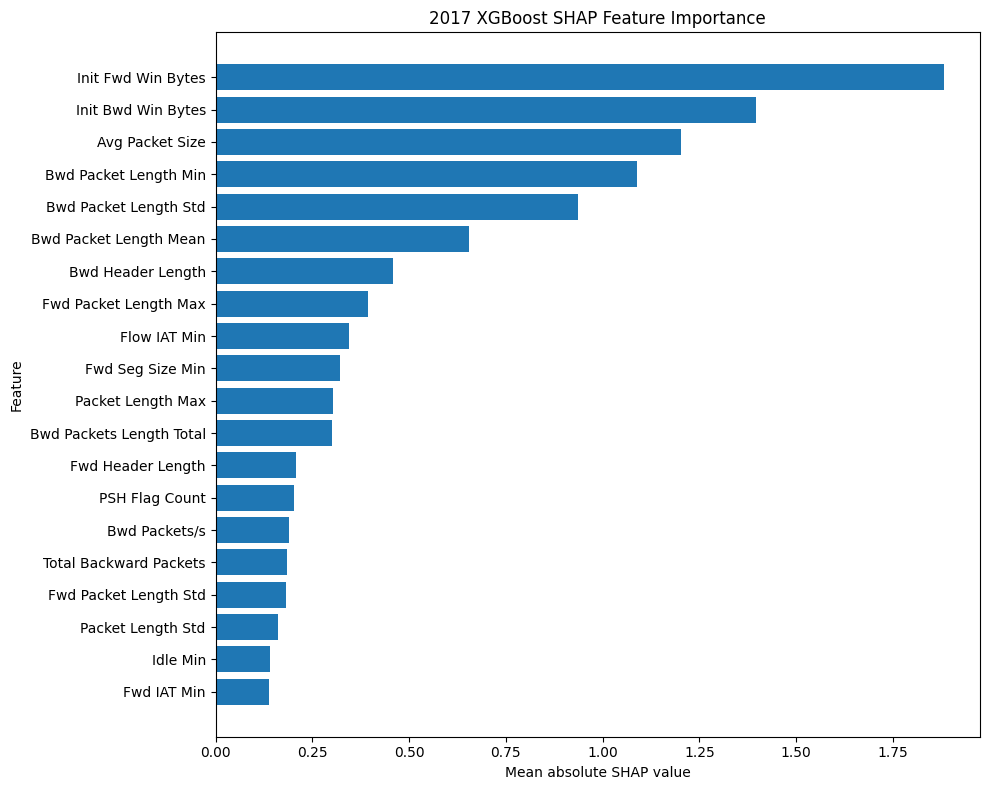

In [ ]:
import matplotlib.pyplot as plt

top20_shap_2017 = shap_importance_2017.head(20).sort_values(
    "Mean_Abs_SHAP"
)

plt.figure(figsize=(10, 8))
plt.barh(
    top20_shap_2017["Feature"],
    top20_shap_2017["Mean_Abs_SHAP"]
)
plt.xlabel("Mean absolute SHAP value")
plt.ylabel("Feature")
plt.title("2017 XGBoost SHAP Feature Importance")
plt.tight_layout()
plt.show()

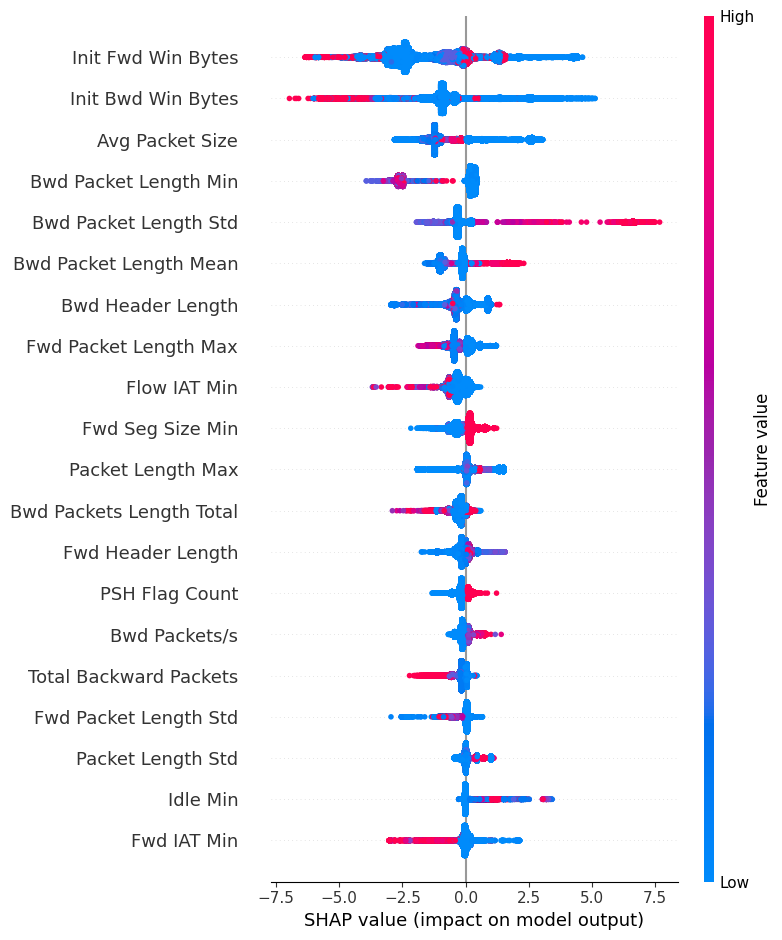

In [ ]:
shap.summary_plot(
    shap_values_2017,
    X_shap_2017,
    feature_names=feature_columns_2017,
    max_display=20,
    show=True
)

In [38]:
X_shap_test_2017, _, y_shap_test_2017, _ = train_test_split(
    X_test_2017,
    y_test_2017,
    train_size=100000,
    stratify=y_test_2017,
    random_state=42
)

print("Test SHAP sample shape:", X_shap_test_2017.shape)
print("Test SHAP target shape:", y_shap_test_2017.shape)
print("Test SHAP attack rate:", y_shap_test_2017.mean())

Test SHAP sample shape: (100000, 68)
Test SHAP target shape: (100000,)
Test SHAP attack rate: 0.197


In [39]:
shap_values_test_2017 = explainer_2017.shap_values(
    X_shap_test_2017
)

print("Test SHAP values shape:", shap_values_test_2017.shape)

Test SHAP values shape: (100000, 68)


In [40]:
shap_importance_test_2017 = pd.DataFrame({
    "Feature": feature_columns_2017,
    "Mean_Abs_SHAP": np.abs(shap_values_test_2017).mean(axis=0)
}).sort_values(
    "Mean_Abs_SHAP",
    ascending=False
).reset_index(drop=True)

print(shap_importance_test_2017.head(20).to_string(index=False))

                 Feature  Mean_Abs_SHAP
      Init Fwd Win Bytes       1.928916
      Init Bwd Win Bytes       1.383650
         Avg Packet Size       1.204975
   Bwd Packet Length Min       1.107560
   Bwd Packet Length Std       0.947848
  Bwd Packet Length Mean       0.661692
       Bwd Header Length       0.451851
   Fwd Packet Length Max       0.393300
            Flow IAT Min       0.340868
        Fwd Seg Size Min       0.322186
Bwd Packets Length Total       0.297169
       Packet Length Max       0.284889
          PSH Flag Count       0.201246
       Fwd Header Length       0.200829
  Total Backward Packets       0.184449
           Bwd Packets/s       0.184231
   Fwd Packet Length Std       0.180256
       Packet Length Std       0.162065
                Idle Min       0.142299
          FIN Flag Count       0.140694


Cross-dataset comparison using SHAP

In [41]:
print("2017 SHAP ranking available:", "shap_importance_2017" in globals())
print("2018 SHAP ranking available:", "shap_importance_2018" in globals())

2017 SHAP ranking available: True
2018 SHAP ranking available: True


In [42]:
shap_comparison = pd.merge(
    shap_importance_2017[["Feature", "Mean_Abs_SHAP"]].rename(
        columns={"Mean_Abs_SHAP": "SHAP_2017"}
    ),
    shap_importance_2018[["Feature", "Mean_Abs_SHAP"]].rename(
        columns={"Mean_Abs_SHAP": "SHAP_2018"}
    ),
    on="Feature",
    how="outer"
).fillna(0)

shap_comparison["Rank_2017"] = (
    shap_comparison["SHAP_2017"]
    .rank(ascending=False, method="min")
)

shap_comparison["Rank_2018"] = (
    shap_comparison["SHAP_2018"]
    .rank(ascending=False, method="min")
)

shap_comparison["Rank_Difference"] = (
    shap_comparison["Rank_2017"] -
    shap_comparison["Rank_2018"]
).abs()

shap_comparison = shap_comparison.sort_values(
    "SHAP_2017",
    ascending=False
).reset_index(drop=True)

print(shap_comparison.head(25).to_string(index=False))

                 Feature  SHAP_2017  SHAP_2018  Rank_2017  Rank_2018  Rank_Difference
      Init Fwd Win Bytes   1.881010   0.980902        1.0        1.0              0.0
      Init Bwd Win Bytes   1.395265   0.409480        2.0        6.0              4.0
         Avg Packet Size   1.202845   0.061069        3.0       30.0             27.0
   Bwd Packet Length Min   1.088027   0.033110        4.0       42.0             38.0
   Bwd Packet Length Std   0.935403   0.364140        5.0        8.0              3.0
  Bwd Packet Length Mean   0.653989   0.074937        6.0       27.0             21.0
       Bwd Header Length   0.459070   0.036622        7.0       41.0             34.0
   Fwd Packet Length Max   0.393639   0.458569        8.0        3.0              5.0
            Flow IAT Min   0.344692   0.242584        9.0       12.0              3.0
        Fwd Seg Size Min   0.322108   0.268566       10.0        9.0              1.0
       Packet Length Max   0.303106   0.244626       1

In [43]:
from scipy.stats import spearmanr

spearman_result = spearmanr(
    shap_comparison["SHAP_2017"].rank(ascending=False),
    shap_comparison["SHAP_2018"].rank(ascending=False)
)

print("Spearman rank correlation:", spearman_result.statistic)
print("p-value:", spearman_result.pvalue)

Spearman rank correlation: 0.5574737324540261
p-value: 7.888292004967179e-07


In [44]:
for k in [5, 10, 20]:
    top_2017 = set(
        shap_importance_2017.head(k)["Feature"]
    )
    
    top_2018 = set(
        shap_importance_2018.head(k)["Feature"]
    )
    
    overlap = top_2017.intersection(top_2018)
    
    print(f"Top-{k} overlap: {len(overlap)}/{k}")
    print("Shared features:", sorted(overlap))
    print()

Top-5 overlap: 1/5
Shared features: ['Init Fwd Win Bytes']

Top-10 overlap: 5/10
Shared features: ['Bwd Packet Length Std', 'Fwd Packet Length Max', 'Fwd Seg Size Min', 'Init Bwd Win Bytes', 'Init Fwd Win Bytes']

Top-20 overlap: 10/20
Shared features: ['Bwd Packet Length Std', 'Bwd Packets Length Total', 'Flow IAT Min', 'Fwd IAT Min', 'Fwd Packet Length Max', 'Fwd Packet Length Std', 'Fwd Seg Size Min', 'Init Bwd Win Bytes', 'Init Fwd Win Bytes', 'Packet Length Max']



In [45]:
print([name for name in globals() if "ks" in name.lower()])

[]
